# 12 - Segmentation semantique : la forme et la surface de chaque defaut

Une classe par pixel (fond / defaut) avec un U-Net dont l'encodeur resnet18 est pre-entraine sur
ImageNet. Donnees : Magnetic Tile (1 344 tuiles magnetiques, masques au pixel, 5 types de
defauts), une surface texturee proche de l'acier.

Ce que tu vas voir, tout le code etant ecrit dans ce notebook :
1. le catalogue image + masque, et pourquoi un decoupage ALEATOIRE serait truque ici
   (la meme tuile photographiee sous plusieurs expositions) : groupes de quasi-doublons ;
2. le decoupage groupe et stratifie ;
3. le masque redimensionne au plus proche voisin, les augmentations qui le suivent ;
4. le modele : U-Net smp, gris copie sur 3 canaux DANS le modele, normalisation et softmax inclus ;
5. la perte CE + Dice ecrite a la main, une boucle d'entrainement avec courbe en direct ;
6. IoU / Dice depuis la matrice de confusion, decision par image, reglage du seuil et de la
   surface minimale sur la VALIDATION ;
7. l'export ONNX verifie et la carte du modele, servie telle quelle par la production.

Prerequis : extra `segmentation` (segmentation_models_pytorch) et
`python tools/get_data/get_magnetic_tile.py`. Poids ImageNet du resnet18 : cache torchvision.

Duree en mode QUICK sur un CPU 2 coeurs : environ 8 minutes (128 px, 8 epoques).

**Le fil** (memes etapes que le cours et que `ETAPES.md`, a la racine de la toolbox) :

```
1 Imports et reglages -> 3 Cataloguer -> 2 Importer et explorer (quasi-doublons) -> 4 Decouper
  -> 5 Pretraiter -> 6 Augmenter -> 8 Modele -> 9 Perte et optimiseur -> 7 Charger par lots
  -> 10 Entrainer -> 11 Evaluer (seuil sur la validation, puis le test)
  -> 12 Sauvegarder et exporter -> 13 Predire (dans "Passer en production")
```

## Etape 1 - Imports et reglages

Une seule cellule : les imports, puis le bloc REGLAGES (tout ce qu'on change pour ses propres
donnees est la, et seulement la), le dossier de sortie et la graine du hasard.

In [1]:
import copy  # copy : copie complete d'un objet (sert a garder les poids du meilleur modele)
import json  # json : ecrit la carte du modele dans un fichier texte lisible
import time  # time : chronometre les etapes et date la carte du modele
import warnings  # warnings : masque les avertissements sans importance
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import cv2  # OpenCV : lecture, ecriture et traitement d'images
import numpy as np  # numpy : calcul sur des tableaux de nombres (une image = un tableau)
import onnxruntime as ort  # onnxruntime : execute un modele au format ONNX (format d'echange, sans PyTorch)
import pandas as pd  # pandas : tableaux de donnees (une ligne par image) faciles a filtrer et a grouper
import segmentation_models_pytorch as smp  # smp : architectures de segmentation pretes a l'emploi (U-Net, FPN...)
import torch  # PyTorch : calcul sur des tenseurs (tableaux de nombres a plusieurs dimensions) et apprentissage
import torch.nn as nn  # nn : briques des reseaux de neurones (couches, modules)
import torch.nn.functional as F  # F : fonctions de calcul sans poids (pertes, softmax, one_hot...)
from IPython.display import display  # display : affiche joliment un tableau dans le notebook
from sklearn.model_selection import StratifiedGroupKFold, train_test_split  # decoupages : par groupes equilibres, ou au hasard
from torch.utils.data import DataLoader, TensorDataset  # TensorDataset emballe les tenseurs ; DataLoader les sert par lots
from torchvision.models import get_model_weights  # acces aux poids pre-entraines des modeles torchvision

from vtb import viz  # viz : affichage de la boite a outils (grilles d'images, courbes, tableaux)

# ---- REGLAGES : tout ce qu'on change pour ses propres donnees ------------------------------
QUICK = True  # True : 128 px, 8 epoques sur CPU ; False : 256 px, 40 epoques (GPU), la configuration nominale
DATA_DIR = Path("data/raw/magnetic_tile")  # <dossier>/<classe>/.../<nom>.jpg + masque <nom>.png a cote
EXTENSIONS = [".jpg"]  # extensions des IMAGES (les .png du meme dossier sont les masques)
COLOR = "gray"  # "rgb" pour des images couleur
IMAGE_SIZE = 128 if QUICK else 256  # cote (en pixels) des images donnees au modele : plus petit = plus rapide, moins de details
EPOCHS = 8 if QUICK else 40  # nombre maximal d'epoques (une epoque = un passage sur toutes les images d'entrainement)
BATCH_SIZE = 16 if QUICK else 8  # images traitees ensemble a chaque pas (un lot, ou batch) : plus grand = plus de memoire
LR = 1e-3 if QUICK else 3e-4  # taux d'apprentissage (taille des pas) du decodeur ; l'encodeur pre-entraine va 10 fois moins vite
ENCODER_LR_FACTOR = 0.1  # facteur du taux de l'encodeur : 0,1 = 10 fois plus lent, pour ne pas effacer ce qu'il a appris
WEIGHT_DECAY = 1e-4  # petite penalite sur la taille des poids : limite le sur-apprentissage
PATIENCE = 4 if QUICK else 8  # arret anticipe apres ce nombre d'epoques sans progres en validation
THRESHOLD = 0.5  # probabilite de defaut au-dessus de laquelle un pixel est defaut (valeur de depart)
MIN_DEFECT_AREA = 10 if QUICK else 20  # pixels (a la taille du modele) pour signaler l'image (valeur de depart)
VAL_FRACTION, TEST_FRACTION = 0.15, 0.2  # 15 % des images en validation (reglages), 20 % en test (note finale)
MAX_HAMMING, MIN_CORRELATION = 6, 0.9  # quasi-doublons : empreinte dHash proche ET details correles
SEED = 42  # graine du hasard : memes tirages a chaque execution, resultats reproductibles
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # calcul sur la carte graphique (GPU) si presente, sinon CPU
OUT = Path("outputs/notebooks/12_segmentation")  # dossier ou ce notebook ecrit ses resultats
# --------------------------------------------------------------------------------------------

OUT.mkdir(parents=True, exist_ok=True)  # cree le dossier de sortie (et ses parents) s'il n'existe pas encore
torch.manual_seed(SEED)  # fixe le hasard de PyTorch (poids initiaux, melanges) : resultats reproductibles
warnings.filterwarnings("ignore", category=UserWarning)  # masque les avertissements d'usage qui encombrent l'affichage
viz.setup_notebook(dpi=80, fmt="jpeg")  # figures en resolution moderee et en jpeg : notebook plus leger
print("device :", DEVICE, "| torch", torch.__version__, "| smp", smp.__version__)  # affiche le materiel et les versions utilises

device : cpu | torch 2.15.0+cu132 | smp 0.6.0


## Etape 3 - Cataloguer : une image, un masque

Rangement attendu : `<DATA_DIR>/<classe>/.../<nom>.jpg` et son masque `<nom>.png` dans le meme
dossier (blanc = defaut). La classe d'image est le premier sous-dossier (MT_Crack, MT_Free...) ;
elle sert a stratifier le decoupage et a compter le rappel par type. Le masque dit si l'image
contient un defaut.

,images,avec_defaut
label,,
MT_Blowhole,115,115
MT_Break,85,85
MT_Crack,57,57
MT_Fray,32,32
MT_Free,952,0
MT_Uneven,103,99


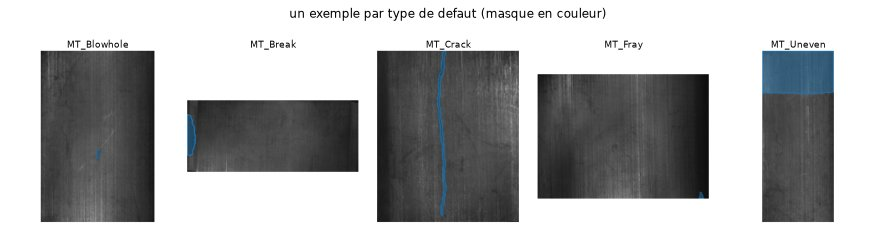

In [2]:
def read_image(path: str | Path, color: str = "rgb") -> np.ndarray:  # lit une image ; renvoie un tableau RGB, gris ou tel quel
    """RGB (H, W, 3) ou gris (H, W), uint8 ou uint16 conserve ; robuste aux chemins Windows avec accents."""
    image = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_UNCHANGED)  # octets du fichier -> image, sans conversion
    if image is None:  # None = le fichier n'est pas une image lisible
        raise ValueError(f"image illisible : {path}")  # on arrete tout de suite avec un message clair
    if image.ndim == 3 and image.shape[2] == 4:  # si l'image a 4 canaux (couleur + transparence "alpha")
        image = image[:, :, :3]  # on garde les 3 canaux de couleur, on jette la transparence
    if color == "unchanged":  # mode "tel quel" : ni gris ni couleur forces
        return cv2.cvtColor(image, cv2.COLOR_BGR2RGB) if image.ndim == 3 else image  # OpenCV lit en BGR : on remet en RGB si couleur
    if color == "gray":  # si on veut du gris
        return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image  # couleur -> gris ; deja gris : inchange
    # sinon RGB : une image grise est copiee sur 3 canaux, une image couleur passe de BGR a RGB
    return np.stack([image] * 3, axis=-1) if image.ndim == 2 else cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def list_images(root: Path, extensions: list[str]) -> list[Path]:  # renvoie la liste triee des images d'un dossier
    """Images triees (l'ordre du disque differe entre Windows et Linux), extension en minuscules."""
    allowed = {e.lower() for e in extensions}  # extensions acceptees, en minuscules (".JPG" vaut ".jpg")
    # tous les fichiers du dossier et de ses sous-dossiers (rglob) dont l'extension est acceptee, tries par chemin
    return sorted(p for p in Path(root).rglob("*") if p.is_file() and p.suffix.lower() in allowed)


def image_mask_catalog(root: Path, extensions: list[str]) -> pd.DataFrame:  # catalogue : une ligne par image avec son masque
    rows = []  # lignes du futur tableau, remplies image par image
    for p in list_images(root, extensions):  # pour chaque image trouvee
        relative = p.relative_to(root)  # chemin relatif au dossier racine, ex. MT_Crack/exp1/x.jpg
        mask = p.parent / f"{p.stem}.png"  # le masque : meme dossier, meme nom, extension .png
        if not mask.exists():  # si le masque est absent
            raise FileNotFoundError(f"masque absent pour {p} : {mask}")  # erreur claire : pas d'entrainement sans masque
        has_defect = bool((read_image(mask, "gray") > 127).any())  # masque blanc = defaut : au moins un pixel blanc ?
        # classe = premier sous-dossier ; image posee directement a la racine : "defect" ou "free" d'apres le masque
        label = relative.parts[0] if len(relative.parts) > 1 else ("defect" if has_defect else "free")
        rows.append({"path": str(p), "label": label, "mask_path": str(mask), "has_defect": has_defect})  # ligne de cette image
    return pd.DataFrame(rows)  # renvoie le tableau pandas (DataFrame) du catalogue


catalog = image_mask_catalog(DATA_DIR, EXTENSIONS)  # catalogue de toutes les images de Magnetic Tile
# par classe : nombre d'images et nombre d'images avec defaut
display(catalog.groupby("label").agg(images=("path", "size"), avec_defaut=("has_defect", "sum")))
example = catalog[catalog["has_defect"]].groupby("label").head(1)  # une image avec defaut par classe, pour l'illustration
viz.grid(  # affiche plusieurs images cote a cote dans une grille
    [  # liste des images a afficher
        viz.overlay_mask(read_image(p, COLOR), (read_image(m, "gray") > 127).astype(np.uint8))  # image + masque 0/1 colore par-dessus
        for p, m in zip(example["path"], example["mask_path"])  # pour chaque couple (image, masque) des exemples
    ],
    example["label"].tolist(),  # titres : la classe de chaque image
    ncols=5,  # 5 images par ligne
    size=2.2,  # largeur de chaque colonne (en pouces)
    suptitle="un exemple par type de defaut (masque en couleur)",  # titre general de la figure
)

## Etape 2 - Importer et explorer : les quasi-doublons, la meme tuile sous plusieurs expositions

Magnetic Tile contient la MEME tuile photographiee sous plusieurs eclairages (fichiers `exp1`,
`exp2`...). Avec un decoupage aleatoire, une copie tombe dans le train et une autre dans le
test : le test mesure alors la memoire du modele, pas sa generalisation. Il faut donc trouver
les groupes de copies et decouper PAR GROUPE.

Deux etapes (celles de `recipes/explore`) :
1. candidats : empreinte dHash (signe du gradient horizontal sur une vignette 9 x 8, 64 bits) a
   au plus 6 bits d'ecart ; rapide (un XOR par paire), mais sur une texture d'acier l'empreinte
   ne voit que l'eclairage : des milliers de faux candidats ;
2. confirmation : correlation des DETAILS (vignette 64 x 64 moins son flou gaussien) >= 0,9.
   Deux textures differentes ont des details independants (correlation proche de 0), deux
   copies une correlation proche de 1.
Les paires confirmees sont reunies en groupes (composantes connexes, union-find).

14348 candidats dHash -> 301 paires confirmees -> 161 groupes de quasi-doublons (418 images) en 2 s


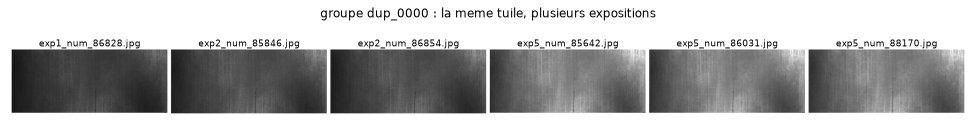

In [3]:
def dhash(gray8: np.ndarray, size: int = 8) -> int:  # empreinte dHash : 64 bits qui resument l'image ; renvoie un entier
    # vignette de 9 colonnes x 8 lignes (9 colonnes donnent 8 comparaisons par ligne), en entiers
    small = cv2.resize(gray8, (size + 1, size), interpolation=cv2.INTER_AREA).astype(np.int16)
    bits = (small[:, 1:] > small[:, :-1]).flatten()  # chaque pixel plus clair que son voisin de gauche ? 8 x 8 = 64 vrai/faux
    return int(np.packbits(bits).view(">u8")[0])  # range les 64 bits dans 8 octets, relus comme un seul entier 64 bits


def to_uint8(image: np.ndarray) -> np.ndarray:  # ramene une image 16 bits en 8 bits (0-255) ; une image 8 bits passe telle quelle
    # 0-65535 -> 0-255 ; le + 0.5 arrondit au plus proche au lieu de tronquer
    return image if image.dtype == np.uint8 else (image.astype(np.float32) / 65535 * 255 + 0.5).astype(np.uint8)


def detail_signature(path: str, size: int = 64) -> np.ndarray:  # signature des details fins : vecteur de 64 x 64 valeurs
    """Vignette sans ses basses frequences, centree et normee : le 'detail' de l'image."""
    # vignette grise 64 x 64 en nombres a virgule (float32) pour les calculs suivants
    small = cv2.resize(to_uint8(read_image(path, "gray")), (size, size), interpolation=cv2.INTER_AREA).astype(np.float32)
    detail = small - cv2.GaussianBlur(small, (0, 0), 3)  # image moins sa version floue = seulement les details fins
    detail -= detail.mean()  # centre : moyenne a 0, l'eclairage global ne compte plus
    # divise par la norme (le contraste ne compte plus ; 1e-6 evite de diviser par 0) puis aplatit en vecteur
    return (detail / max(float(np.linalg.norm(detail)), 1e-6)).ravel()


def duplicate_groups(paths: list[str]) -> tuple[pd.DataFrame, int, int]:  # renvoie (groupe de chaque image, nb candidats, nb paires)
    import hashlib  # hashlib : empreinte MD5, identique seulement pour deux fichiers identiques octet par octet

    hashes, md5 = [], []  # une empreinte dHash et une empreinte MD5 par image
    for p in paths:  # pour chaque image du catalogue
        image = read_image(p, "unchanged")  # lecture sans conversion (8 ou 16 bits, gris ou couleur)
        gray = image if image.ndim == 2 else cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)  # passe en gris si l'image est en couleur
        hashes.append(dhash(to_uint8(gray)))  # empreinte dHash de l'image ramenee en 8 bits
        md5.append(hashlib.md5(Path(p).read_bytes()).hexdigest())  # empreinte MD5 des octets du fichier
    hashes = np.array(hashes, dtype=np.uint64)  # tableau d'entiers 64 bits sans signe, pour les calculs bit a bit
    candidates = []  # paires (i, j) d'images aux empreintes proches
    for i in range(len(paths) - 1):  # pour chaque image (sauf la derniere), comparee a toutes les suivantes
        # XOR : 1 la ou les bits different ; bitwise_count compte ces 1 = distance de Hamming
        distances = np.bitwise_count(hashes[i] ^ hashes[i + 1 :])
        candidates.extend((i, i + 1 + int(o)) for o in np.flatnonzero(distances <= MAX_HAMMING))  # paires a 6 bits d'ecart au plus
    signatures: dict[int, np.ndarray] = {}  # memoire (cache) : signature deja calculee pour chaque indice d'image

    def signature(k: int) -> np.ndarray:  # renvoie la signature de l'image k, calculee une seule fois
        if k not in signatures:  # si elle n'est pas encore en memoire
            signatures[k] = detail_signature(paths[k])  # on la calcule et on la range
        return signatures[k]  # renvoie la signature gardee en memoire

    # paires confirmees : fichiers identiques (MD5) ou details correles a >= 0,9 (@ = produit scalaire = correlation ici)
    pairs = [(i, j) for i, j in candidates if md5[i] == md5[j] or float(signature(i) @ signature(j)) >= MIN_CORRELATION]
    parent = {p: p for p in paths}  # union-find : chaque image est d'abord son propre groupe ; chaque paire confirmee en reunit deux

    def root(p: str) -> str:  # renvoie le representant (la racine) du groupe de l'image p
        while parent[p] != p:  # tant que p n'est pas sa propre racine, on remonte
            parent[p] = parent[parent[p]]  # raccourci : p pointe vers son grand-parent (chemins plus courts ensuite)
            p = parent[p]  # on monte d'un cran
        return p  # p est la racine du groupe

    for i, j in pairs:  # pour chaque paire confirmee
        parent[root(paths[i])] = root(paths[j])  # fusionne les deux groupes : une racine pointe vers l'autre
    roots = {p: root(p) for p in paths}  # racine finale de chaque image
    sizes = pd.Series(list(roots.values())).value_counts()  # nombre d'images par racine = taille de chaque groupe
    # groupes de 2+ images : dup_0000... ; une image seule est son propre groupe
    names = {r: f"dup_{k:04d}" for k, r in enumerate(sizes[sizes > 1].index)}
    # tableau chemin -> groupe ("dup_XXXX", ou le chemin lui-meme pour une image seule), plus les deux compteurs
    return pd.DataFrame({"path": paths, "group": [names.get(roots[p], p) for p in paths]}), len(candidates), len(pairs)


start = time.time()  # heure de depart, pour chronometrer
groups, n_candidates, n_pairs = duplicate_groups(catalog["path"].tolist())  # cherche les quasi-doublons parmi toutes les images
catalog = catalog.merge(groups, on="path")  # ajoute la colonne "group" au catalogue (jointure sur le chemin)
duplicated = catalog[catalog["group"].str.startswith("dup_")]  # seulement les images qui ont au moins un quasi-doublon
print(  # bilan de la recherche
    # candidats, paires, groupes
    f"{n_candidates} candidats dHash -> {n_pairs} paires confirmees -> {duplicated['group'].nunique()} groupes "
    f"de quasi-doublons ({len(duplicated)} images) en {time.time() - start:.0f} s"  # images concernees et duree
)
biggest = duplicated["group"].value_counts().index[0]  # nom du plus gros groupe de quasi-doublons
members = catalog[catalog["group"] == biggest]  # les images de ce groupe
viz.grid(  # les affiche cote a cote
    [read_image(p, COLOR) for p in members["path"]],  # les images du groupe
    [Path(p).name[:18] for p in members["path"]],  # titres : les 18 premiers caracteres du nom de fichier
    ncols=min(6, len(members)),  # au plus 6 images par ligne
    size=2.0,  # largeur de chaque colonne (pouces)
    suptitle=f"groupe {biggest} : la meme tuile, plusieurs expositions",  # titre general
)

## Etape 4 - Decouper : le decoupage groupe et stratifie

`StratifiedGroupKFold` a 5 plis donne des plis de 1/5 qui respectent les groupes (aucun groupe
coupe) en equilibrant les classes : le premier pli devient le test (20 %), puis on recommence
sur le reste pour la validation (15 % du total). Meme algorithme et meme graine que la recette :
le decoupage est identique a `outputs/segmentation/tile_split.csv`.

A titre de comparaison, on compte combien de groupes un decoupage aleatoire stratifie couperait.

In [4]:
def holdout_grouped(frame: pd.DataFrame, fraction: float, seed: int) -> pd.Index:  # met de cote ~fraction des lignes ; renvoie leurs index
    """Environ `fraction` des lignes, sans couper aucun groupe, en equilibrant les classes."""
    n_splits = max(2, round(1 / fraction))  # nombre de plis : 0,2 -> 5 plis de 20 % chacun
    # plis qui gardent chaque groupe entier et ont les memes proportions de classes (stratifie), melanges avec la graine
    folds = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    _, held = next(folds.split(frame, frame["label"].astype(str), groups=frame["group"]))  # premier pli seulement : positions mises de cote
    return frame.index[held]  # convertit ces positions en index du tableau


split = catalog.copy().reset_index(drop=True)  # copie du catalogue, lignes renumerotees 0, 1, 2...
split["split"] = "train"  # par defaut, chaque image va a l'entrainement
split.loc[holdout_grouped(split, TEST_FRACTION, SEED), "split"] = "test"  # 20 % des images, groupes entiers, passent en test
rest = split[split["split"] == "train"]  # ce qui reste pour l'entrainement
# 15 % du total, pris dans le reste -> validation
split.loc[holdout_grouped(rest, VAL_FRACTION / (1 - TEST_FRACTION), SEED), "split"] = "val"
crossing = split.groupby("group")["split"].nunique()  # pour chaque groupe : dans combien de parties ses images sont tombees
assert (crossing == 1).all(), "un groupe est coupe : fuite"  # chaque groupe doit tenir dans une seule partie, sinon fuite vers le test
split.to_csv(OUT / "split.csv", index=False)  # sauvegarde le decoupage (une ligne par image)
display(pd.crosstab(split["label"], split["split"], margins=True))  # nombre d'images par classe et par partie, avec totaux

# comparaison : test tire au hasard (stratifie = memes proportions de classes), sans tenir compte des groupes
_, random_test = train_test_split(catalog.index, test_size=TEST_FRACTION, stratify=catalog["label"], random_state=SEED)
random_split = pd.Series("train", index=catalog.index)  # toutes les images en train ...
random_split[random_test] = "test"  # ... sauf celles tirees pour le test
cut = catalog.assign(s=random_split).groupby("group")["s"].nunique()  # nombre de parties touchees par chaque groupe dans ce tirage
# groupes coupes (presents en train ET en test) : autant de fuites
print(f"decoupage aleatoire : {int((cut > 1).sum())} groupes coupes entre train et test (autant de copies vues a l'entrainement)")

split,test,train,val,All
label,,,,
MT_Blowhole,23,73,19,115
MT_Break,17,54,14,85
MT_Crack,11,37,9,57
MT_Fray,7,20,5,32
MT_Free,190,610,152,952
MT_Uneven,21,66,16,103
All,269,860,215,1344


decoupage aleatoire : 64 groupes coupes entre train et test (autant de copies vues a l'entrainement)


## Etapes 5 et 6 - Pretraiter et augmenter : images et masques en memoire

- Image : resize de la toolbox (INTER_AREA pour reduire) puis valeurs dans [0, 1].
- Masque : 0 / 1 puis resize au PLUS PROCHE VOISIN (une interpolation creerait des classes
  intermediaires) ; c'est aussi pourquoi un recadrage du pretraitement est interdit : il
  deplacerait l'image sans deplacer le masque.
- Augmentations (entrainement seulement) : retournements horizontal et vertical, appliques AU
  MEME TIRAGE a l'image et au masque.

Le defaut occupe une toute petite part des pixels : un modele qui repond "fond" partout aurait
99 % de pixels justes. D'ou la perte Dice et des metriques sur les classes de DEFAUT.

lecture 2 s | train (860, 1, 128, 128) val (215, 1, 128, 128) test (269, 1, 128, 128)
part des pixels de defaut (train) : 2.57%


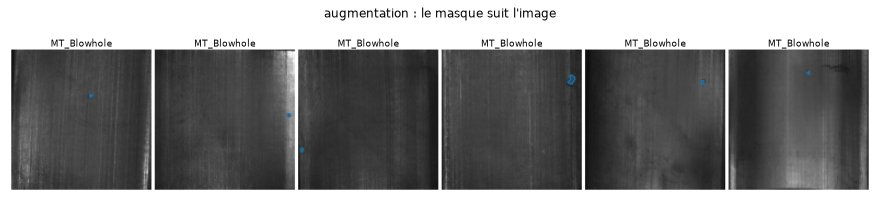

In [5]:
CLASS_NAMES = ["background", "defect"]  # classes des pixels : indice 0 = fond, indice 1 = defaut


def resize(image: np.ndarray, size: int) -> np.ndarray:  # redimensionne une image en carre size x size
    shrinking = size * size < image.shape[0] * image.shape[1]  # vrai si l'image est reduite (moins de pixels a l'arrivee)
    # INTER_AREA pour reduire (moyenne les pixels, sans crenelage), interpolation lineaire pour agrandir
    return cv2.resize(image, (size, size), interpolation=cv2.INTER_AREA if shrinking else cv2.INTER_LINEAR)


def load_subset(name: str) -> tuple[pd.DataFrame, torch.Tensor, torch.Tensor]:  # charge une partie ; renvoie (tableau, images, masques)
    frame = split[split["split"] == name].reset_index(drop=True)  # lignes de cette partie (train, val ou test), renumerotees
    images = np.stack([resize(read_image(p, COLOR), IMAGE_SIZE) for p in frame["path"]])  # lit, redimensionne et empile : (N, H, W)
    masks = np.stack(  # empile les masques en un tableau (N, H, W)
        [  # un masque par image
            # masque 0/1 redimensionne au plus proche voisin : chaque pixel reste 0 ou 1, jamais une valeur intermediaire
            cv2.resize((read_image(m, "gray") > 127).astype(np.uint8), (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_NEAREST)
            for m in frame["mask_path"]  # pour chaque chemin de masque
        ]
    )
    peak = 65535.0 if images.dtype == np.uint16 else 255.0  # valeur maximale possible : 65535 en 16 bits, 255 en 8 bits
    x = torch.from_numpy(images.astype(np.float32) / peak)  # tenseur PyTorch de nombres a virgule dans [0, 1]
    # format (N, C, H, W) attendu par PyTorch : ajoute l'axe canal (gris) ou le deplace devant (couleur)
    x = x[:, None] if x.ndim == 3 else x.permute(0, 3, 1, 2).contiguous()
    return frame, x, torch.from_numpy(masks.astype(np.int64))  # masques en entiers 64 bits : type attendu par la perte


start = time.time()  # chrono de la lecture
train_df, x_train, y_train = load_subset("train")  # entrainement : les poids apprennent sur ces images
val_df, x_val, y_val = load_subset("val")  # validation : sert a choisir l'epoque et les reglages
test_df, x_test, y_test = load_subset("test")  # test : la note finale, lue une seule fois
# duree de lecture et formes des tenseurs (N, C, H, W)
print(f"lecture {time.time() - start:.0f} s | train {tuple(x_train.shape)} val {tuple(x_val.shape)} test {tuple(x_test.shape)}")
print(f"part des pixels de defaut (train) : {float((y_train > 0).float().mean()):.2%}")  # montre le desequilibre fond / defaut


def augment(x: torch.Tensor, y: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:  # retourne au hasard images et masques ensemble
    """Retournements tires par image, appliques a l'image ET au masque."""
    x, y = x.clone(), y.clone()  # copies : les tenseurs d'origine ne sont pas modifies
    for dim in (-1, -2):  # deux axes : -1 = largeur (retournement horizontal), -2 = hauteur (vertical)
        flip = torch.rand(len(x)) < 0.5  # tirage par image : vrai pour environ la moitie du lot
        x[flip], y[flip] = x[flip].flip(dim), y[flip].flip(dim)  # retourne ces images ET leurs masques de la meme facon
    return x, y  # lot augmente : images et masques restent alignes


xa, ya = augment(x_train[:6], y_train[:6])  # augmente les 6 premieres images pour verifier a l'oeil
viz.grid(  # grille de controle
    [viz.overlay_mask((xa[i, 0].numpy() * 255).astype(np.uint8), ya[i].numpy()) for i in range(6)],  # image en 0-255 + masque superpose
    train_df["label"].tolist()[:6],  # titres : la classe de chaque image
    ncols=6,  # 6 images sur une ligne
    size=1.8,  # largeur de chaque colonne (pouces)
    suptitle="augmentation : le masque suit l'image",  # titre general
)

## Etapes 8 et 9 - Modele, perte et optimiseur : U-Net, encodeur pre-entraine, tout ce qu'il faut DANS le graphe

- `smp.Unet(encoder_name="resnet18")` : l'encodeur descend jusqu'a 1/32, le decodeur remonte a
  la resolution de l'image avec des connexions directes (les details fins des premieres couches).
- Poids ImageNet de torchvision charges dans l'encodeur ; le decodeur part de zero : deux taux
  d'apprentissage (encodeur 10 fois plus lent, pour ne pas detruire ce qu'il sait).
- Image grise : copiee sur 3 canaux DANS le modele, puis normalisation ImageNet canal par canal.
  La reponse est exactement celle des poids ImageNet, et la production envoie toujours 1 canal.
- `forward` rend les probabilites (softmax) ; `logits` sert a la perte.

In [6]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # moyenne et ecart-type par canal (R, G, B) d'ImageNet


class Segmenter(nn.Module):  # enveloppe du U-Net : gris copie sur 3 canaux, normalisation, softmax, tout dans le modele
    """Image (N, C, H, W) dans [0, 1] -> probabilites (N, K, H, W)."""

    def __init__(self, net: nn.Module, repeat: int) -> None:  # construit le module a partir du reseau et du nombre de copies du canal
        super().__init__()  # initialise la partie nn.Module (obligatoire pour enregistrer les couches)
        self.net, self.repeat = net, repeat  # garde le reseau et le nombre de copies du canal (3 pour une image grise)
        # buffer : constante rangee dans le modele (sauvee et exportee avec lui) ; forme (1, 3, 1, 1) pour agir canal par canal
        self.register_buffer("mean", torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(IMAGENET_STD).view(1, 3, 1, 1))  # ecart-type ImageNet, meme principe

    def logits(self, x: torch.Tensor) -> torch.Tensor:  # renvoie les logits : scores bruts par classe et par pixel, avant softmax
        if self.repeat > 1:  # si l'image n'a qu'un canal (gris)
            x = x.repeat(1, self.repeat, 1, 1)  # copie le canal 3 fois : l'encodeur ImageNet attend 3 canaux
        # normalisation (on retire la moyenne et on divise par l'ecart-type d'ImageNet) puis passage dans le U-Net
        return self.net((x - self.mean) / self.std)

    def forward(self, x: torch.Tensor) -> torch.Tensor:  # appel normal du modele : renvoie les probabilites
        return torch.softmax(self.logits(x), dim=1)  # softmax : logits -> probabilites positives qui somment a 1 sur les classes


in_channels = int(x_train.shape[1])  # nombre de canaux des images (1 en gris)
# U-Net : encodeur resnet18 a 3 canaux d'entree, une carte de sortie par classe ; poids ImageNet charges juste apres
net = smp.Unet(encoder_name="resnet18", encoder_weights=None, in_channels=3, classes=len(CLASS_NAMES))
# charge dans l'encodeur les poids appris sur ImageNet (fichier deja present dans le cache torchvision)
net.encoder.load_state_dict(get_model_weights("resnet18").DEFAULT.get_state_dict(progress=False))  # ImageNet, cache torchvision
model = Segmenter(net, repeat=3 if in_channels == 1 else 1).to(DEVICE)  # modele complet, envoye sur le GPU ou le CPU
encoder_params = list(model.net.encoder.parameters())  # poids de l'encodeur (pre-entraine)
encoder_ids = {id(p) for p in encoder_params}  # leurs identifiants, pour les reconnaitre ensuite
# optimiseur AdamW : corrige les poids a chaque pas d'apres le gradient (direction qui fait baisser l'erreur)
optimizer = torch.optim.AdamW(
    [  # deux groupes de poids, chacun avec son taux d'apprentissage
        {"params": encoder_params, "lr": LR * ENCODER_LR_FACTOR},  # encodeur : 10 fois plus lent, pour ne pas detruire ce qu'il sait
        {"params": [p for p in model.parameters() if id(p) not in encoder_ids], "lr": LR},  # tout le reste (decodeur) : taux normal
    ],
    weight_decay=WEIGHT_DECAY,  # penalite sur la taille des poids
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)  # le taux baisse en douceur (cosinus) jusqu'a la fin
# nombre total de parametres (poids appris) et part de l'encodeur
print(f"{sum(p.numel() for p in model.parameters()):,} parametres dont {sum(p.numel() for p in encoder_params):,} dans l'encodeur")

14,328,354 parametres dont 11,176,512 dans l'encodeur


## Etapes 9 et 11 - Perte et optimiseur, evaluer : la perte CE + Dice, et les metriques depuis la matrice de confusion

- Entropie croisee : pixel par pixel (domine par le fond).
- Dice : 1 - 2 |A inter B| / (|A| + |B|) par classe, calcule sur tout le lot : un recouvrement
  global, insensible au nombre de pixels de fond. Les classes absentes du lot sont ignorees.
  (C'est la `DiceLoss("multiclass")` de segmentation_models_pytorch, reecrite.)
- Metriques : une matrice de confusion des pixels (lignes = verite, colonnes = prediction), puis
  IoU = TP / (TP + FP + FN) et Dice = 2 TP / (2 TP + FP + FN) par classe. On rapporte la moyenne
  sur les classes de DEFAUT : le fond (IoU 0,99) gonflerait tout.
- Decision binaire : pixel defaut si P(defaut) > seuil (a 0,5 c'est l'argmax).

In [7]:
def dice_loss(logits: torch.Tensor, target: torch.Tensor, eps: float = 1e-7) -> torch.Tensor:  # perte Dice : 1 - recouvrement, par classe
    probs = logits.softmax(dim=1)  # probabilites par classe et par pixel (N, K, H, W)
    # verite en "one-hot" : un canal par classe, 1 la ou le pixel est de cette classe, 0 ailleurs ; remis en (N, K, H, W)
    onehot = F.one_hot(target, logits.shape[1]).permute(0, 3, 1, 2).float()
    dims = (0, 2, 3)  # axes a additionner : images du lot, hauteur, largeur -> il reste un nombre par classe
    intersection = (probs * onehot).sum(dims)  # |A inter B| : probabilite donnee aux bons pixels, par classe
    cardinality = (probs + onehot).sum(dims)  # |A| + |B| : taille de la prediction + taille de la verite, par classe
    loss = 1 - 2 * intersection / cardinality.clamp_min(eps)  # 1 - Dice par classe ; clamp_min evite une division par 0
    present = onehot.sum(dims) > 0  # classes presentes dans la verite du lot
    return (loss * present).mean()  # moyenne sur les classes ; une classe absente compte 0 (elle ne pousse pas le modele)


def criterion(logits: torch.Tensor, target: torch.Tensor) -> torch.Tensor:  # perte totale a minimiser : entropie croisee + Dice
    return F.cross_entropy(logits, target) + dice_loss(logits, target)  # entropie croisee : erreur pixel par pixel ; Dice : recouvrement


def predict_classes(probs: torch.Tensor, threshold: float) -> torch.Tensor:  # probabilites -> classe de chaque pixel (N, H, W)
    # 2 classes : defaut si P(defaut) > seuil ; plus de 2 classes : la plus probable (argmax)
    return (probs[:, 1] > threshold).long() if probs.shape[1] == 2 else probs.argmax(dim=1)


def confusion(pred: np.ndarray, truth: np.ndarray, k: int) -> np.ndarray:  # matrice de confusion k x k (lignes verite, colonnes prediction)
    index = truth.astype(np.int64).ravel() * k + pred.astype(np.int64).ravel()  # numero de case de chaque pixel : verite x k + prediction
    return np.bincount(index, minlength=k * k).reshape(k, k)  # compte les pixels de chaque case, range en tableau k x k


def scores_from_confusion(matrix: np.ndarray) -> dict:  # IoU et Dice depuis la matrice ; renvoie un dictionnaire de moyennes
    tp = np.diag(matrix).astype(np.float64)  # vrais positifs (TP) par classe : la diagonale (verite = prediction)
    fp, fn = matrix.sum(0) - tp, matrix.sum(1) - tp  # faux positifs (colonne moins TP), faux negatifs (ligne moins TP)
    with np.errstate(invalid="ignore", divide="ignore"):  # pas d'avertissement si une classe est absente (0 / 0 donne nan)
        iou, dice = tp / (tp + fp + fn), 2 * tp / (2 * tp + fp + fn)  # IoU = intersection / union ; Dice = 2 x inter. / somme des tailles
    defects = [c for c in range(1, len(matrix)) if matrix[c].sum() > 0]  # classes de defaut (pas le fond 0) presentes dans la verite
    return {  # dictionnaire des scores
        "miou": float(np.nanmean(iou)),  # IoU moyen sur toutes les classes (nanmean ignore les nan)
        "miou_defects": float(np.nanmean(iou[defects])),  # IoU moyen des classes de defaut : la metrique principale
        "mdice_defects": float(np.nanmean(dice[defects])),  # Dice moyen des classes de defaut
        "iou_background": float(iou[0]),  # IoU du fond (toujours tres haut, a titre indicatif)
    }


@torch.no_grad()  # pas de calcul de gradient dans cette fonction : plus rapide, moins de memoire
def predict_probs(x: torch.Tensor) -> torch.Tensor:  # probabilites du modele pour toutes les images ; renvoie (N, K, H, W)
    model.eval()  # mode evaluation : BatchNorm utilise ses statistiques apprises, plus de hasard
    return torch.cat([model(x[i : i + 32].to(DEVICE)).cpu() for i in range(0, len(x), 32)])  # 32 images a la fois, recollees sur CPU

## Etapes 7 et 10 - Charger par lots, entrainer : le meilleur IoU de defaut en validation garde le modele

Une epoque : lots melanges, augmentation, perte, retropropagation, ecretage du gradient (1,0).
Apres chaque epoque : IoU des defauts sur la validation ; le meilleur etat est garde, et l'on
s'arrete apres `PATIENCE` epoques sans progres. La courbe se met a jour pendant l'entrainement.

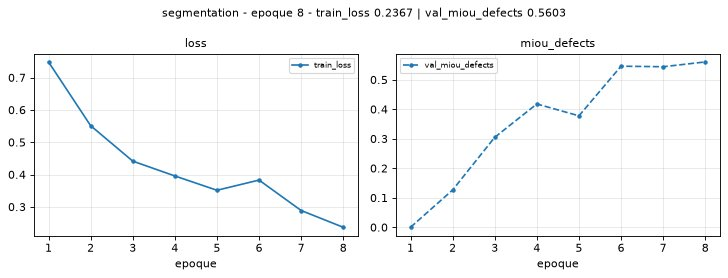

entrainement 375 s | meilleure epoque 8 | IoU defauts (validation) 0.560


In [8]:
loader = DataLoader(  # distribue les donnees d'entrainement lot par lot
    TensorDataset(x_train, y_train),  # les donnees : couples (image, masque) pris dans les deux tenseurs
    batch_size=BATCH_SIZE,  # nombre d'images par lot
    shuffle=True,  # ordre melange a chaque epoque : le modele ne voit pas toujours la meme suite
    drop_last=True,  # jette le dernier lot s'il est incomplet (BatchNorm supporte mal les tout petits lots)
    generator=torch.Generator().manual_seed(SEED),  # tirage du melange avec une graine fixe : reproductible
)
live = viz.LivePlot(metrics=("train_loss", "val_miou_defects"), title="segmentation")  # courbes mises a jour en direct
best, best_state, best_epoch, bad = -1.0, None, 0, 0  # meilleur score vu, poids correspondants, son epoque, epoques sans progres
start = time.time()  # chrono de l'entrainement
for epoch in range(1, EPOCHS + 1):  # pour chaque epoque (1, 2, ..., EPOCHS)
    model.train()  # mode entrainement : BatchNorm suit les statistiques de chaque lot
    total, seen = 0.0, 0  # somme des pertes et nombre d'images vues dans l'epoque
    for xb, yb in loader:  # pour chaque lot (images xb, masques yb)
        xb, yb = augment(xb, yb)  # retournements aleatoires, image et masque ensemble
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)  # envoie le lot sur le GPU ou le CPU
        optimizer.zero_grad(set_to_none=True)  # efface les gradients du lot precedent (sinon ils s'additionnent)
        loss = criterion(model.logits(xb), yb)  # perte du lot, calculee sur les logits (plus stable numeriquement)
        loss.backward()  # retropropagation : calcule le gradient de la perte pour chaque poids
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # ecretage : la taille totale du gradient est limitee a 1 (pas trop brutaux)
        optimizer.step()  # corrige les poids dans la direction qui fait baisser la perte
        total, seen = total + loss.item() * len(xb), seen + len(xb)  # cumule la perte (ponderee par la taille du lot) et les images
    scheduler.step()  # fin d'epoque : le planning baisse le taux d'apprentissage
    # IoU / Dice sur la validation, avec le seuil de depart
    val = scores_from_confusion(confusion(predict_classes(predict_probs(x_val), THRESHOLD).numpy(), y_val.numpy(), len(CLASS_NAMES)))
    live.update(epoch, train_loss=total / seen, val_miou_defects=val["miou_defects"])  # ajoute un point aux courbes
    if val["miou_defects"] > best + 1e-4:  # si l'IoU des defauts progresse (d'au moins 0,0001)
        # garde ce score, une copie complete des poids et l'epoque ; compteur sans progres remis a 0
        best, best_state, best_epoch, bad = val["miou_defects"], copy.deepcopy(model.state_dict()), epoch, 0
    else:  # sinon (pas de progres)
        bad += 1  # une epoque de plus sans progres
        if bad >= PATIENCE:  # si trop d'epoques sans progres
            break  # arret anticipe : inutile de continuer
live.close()  # fige la courbe finale
train_seconds = time.time() - start  # duree de l'entrainement en secondes
model.load_state_dict(best_state)  # recharge les poids de la meilleure epoque
print(f"entrainement {train_seconds:.0f} s | meilleure epoque {best_epoch} | IoU defauts (validation) {best:.3f}")  # bilan

## Etape 11 - Evaluer : regler le seuil et la surface minimale sur la VALIDATION

La decision de production est souvent par image : "au moins N pixels de defaut". Deux reglages
la gouvernent : le seuil de probabilite et la surface minimale. On les choisit sur la
validation (jamais sur le test) : ici, le plus grand rappel image avec au plus 2 % de fausses
alarmes sur les tuiles saines de validation.

In [9]:
val_probs = predict_probs(x_val)  # probabilites sur toute la validation
val_has_defect = (y_val.flatten(1) > 0).any(dim=1).numpy()  # pour chaque image : la verite contient-elle un pixel de defaut ?
rows = []  # une ligne par couple (seuil, surface minimale)
for threshold in (0.3, 0.4, 0.5, 0.6, 0.7):  # pour chaque seuil de probabilite essaye
    areas = (val_probs[:, 1] > threshold).flatten(1).sum(dim=1).numpy()  # nombre de pixels de defaut predits dans chaque image
    for area in (1, 5, 10, 20, 40):  # pour chaque surface minimale essayee (en pixels)
        flagged = areas >= area  # images signalees : assez de pixels de defaut
        rows.append(  # ajoute le resultat de ce couple de reglages
            {  # une ligne du tableau
                "seuil": threshold,  # seuil de probabilite teste
                "surface_min": area,  # surface minimale testee
                "rappel_image": float(flagged[val_has_defect].mean()),  # rappel : part des images a defaut bien signalees
                "fausses_alarmes": float(flagged[~val_has_defect].mean()),  # part des images saines signalees a tort (~ = non)
            }
        )
sweep = pd.DataFrame(rows)  # tableau de tous les essais
print("rappel image sur la validation (lignes : seuil, colonnes : surface minimale)")  # titre du tableau suivant
display(sweep.pivot(index="seuil", columns="surface_min", values="rappel_image").round(3))  # rappel en tableau seuil x surface
print("fausses alarmes image sur la validation")  # titre du tableau suivant
display(sweep.pivot(index="seuil", columns="surface_min", values="fausses_alarmes").round(3))  # fausses alarmes, seuil x surface
admissible = sweep[sweep["fausses_alarmes"] <= 0.02]  # reglages acceptables : au plus 2 % de fausses alarmes
# parmi eux (ou tous si aucun) : le meilleur rappel, puis le moins de fausses alarmes ; iloc[0] prend le premier
chosen = (admissible if len(admissible) else sweep).sort_values(["rappel_image", "fausses_alarmes"], ascending=[False, True]).iloc[0]
chosen_threshold, chosen_area = float(chosen["seuil"]), int(chosen["surface_min"])  # les deux reglages retenus
print(f"choisi sur la validation : seuil {chosen_threshold}, surface minimale {chosen_area} pixels")  # affiche le choix

rappel image sur la validation (lignes : seuil, colonnes : surface minimale)


surface_min,1,5,10,20,40
seuil,,,,,
0.3,0.387,0.387,0.371,0.371,0.355
0.4,0.371,0.371,0.371,0.355,0.339
0.5,0.339,0.339,0.339,0.339,0.339
0.6,0.339,0.339,0.339,0.339,0.339
0.7,0.339,0.339,0.339,0.339,0.323


fausses alarmes image sur la validation


surface_min,1,5,10,20,40
seuil,,,,,
0.3,0.033,0.033,0.033,0.026,0.02
0.4,0.033,0.033,0.026,0.020,0.02
0.5,0.033,0.026,0.026,0.020,0.02
0.6,0.026,0.026,0.020,0.020,0.02
0.7,0.020,0.020,0.020,0.020,0.02


choisi sur la validation : seuil 0.3, surface minimale 40 pixels


## Etape 11 - Evaluer : le test, lu une seule fois

Deux lignes : les reglages de depart de la recette (0,5 et `MIN_DEFECT_AREA`) et ceux choisis
sur la validation. L'IoU / Dice des defauts mesure la qualite du contour ; le rappel image et
les fausses alarmes, la decision de tri. Le rappel par type montre ou le modele peine.

,miou,miou_defects,mdice_defects,iou_background,seuil,surface_min,image_recall,image_false_alarm_rate
reglages de depart,0.741,0.494,0.661,0.987,0.5,10.0,0.304,0.0
choisis sur la validation,0.746,0.505,0.671,0.987,0.3,40.0,0.278,0.0


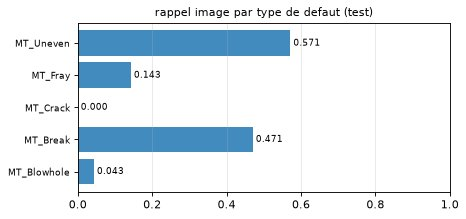

In [10]:
start = time.time()  # chrono de la prediction sur le test
test_probs = predict_probs(x_test)  # probabilites sur tout le test
ms_per_image = 1000 * (time.time() - start) / len(x_test)  # temps moyen par image, en millisecondes
test_has_defect = (y_test.flatten(1) > 0).any(dim=1).numpy()  # verite par image : contient un defaut ou non


def test_report(threshold: float, area: int) -> tuple[dict, np.ndarray]:  # metriques du test ; renvoie (scores, images signalees)
    pred = predict_classes(test_probs, threshold)  # classe de chaque pixel avec ce seuil
    report = scores_from_confusion(confusion(pred.numpy(), y_test.numpy(), len(CLASS_NAMES)))  # IoU / Dice des pixels
    flagged = pred.flatten(1).sum(dim=1).numpy() >= area  # images signalees : au moins `area` pixels de defaut
    report.update(  # ajoute les metriques par image au dictionnaire
        {  # nouvelles cles
            "seuil": threshold,  # seuil utilise
            "surface_min": area,  # surface minimale utilisee
            "image_recall": float(flagged[test_has_defect].mean()),  # rappel image : part des images a defaut signalees
            "image_false_alarm_rate": float(flagged[~test_has_defect].mean()),  # part des images saines signalees a tort
        }
    )
    return report, flagged  # scores et decision par image


start_report, _ = test_report(THRESHOLD, MIN_DEFECT_AREA)  # test avec les reglages de depart (decisions jetees : _)
chosen_report, flagged = test_report(chosen_threshold, chosen_area)  # test avec les reglages choisis sur la validation
metrics = {"reglages de depart": start_report, "choisis sur la validation": chosen_report}  # les deux lignes du tableau
display(viz.metrics_table(metrics))  # affiche les metriques cote a cote
# rappel image par type de defaut : moyenne des decisions, groupees par classe d'image
per_type = pd.Series(flagged[test_has_defect], index=test_df.loc[test_has_defect, "label"]).groupby(level=0).mean()
viz.per_class_bars(per_type, title="rappel image par type de defaut (test)")  # diagramme en barres du rappel par type

### Image, verite, prediction

Les plus petits trous (MT_Blowhole) ne font que quelques pixels a 128 px : ils passent souvent
sous la surface minimale. Le levier est la resolution (256 px en mode complet) ou des tuiles.

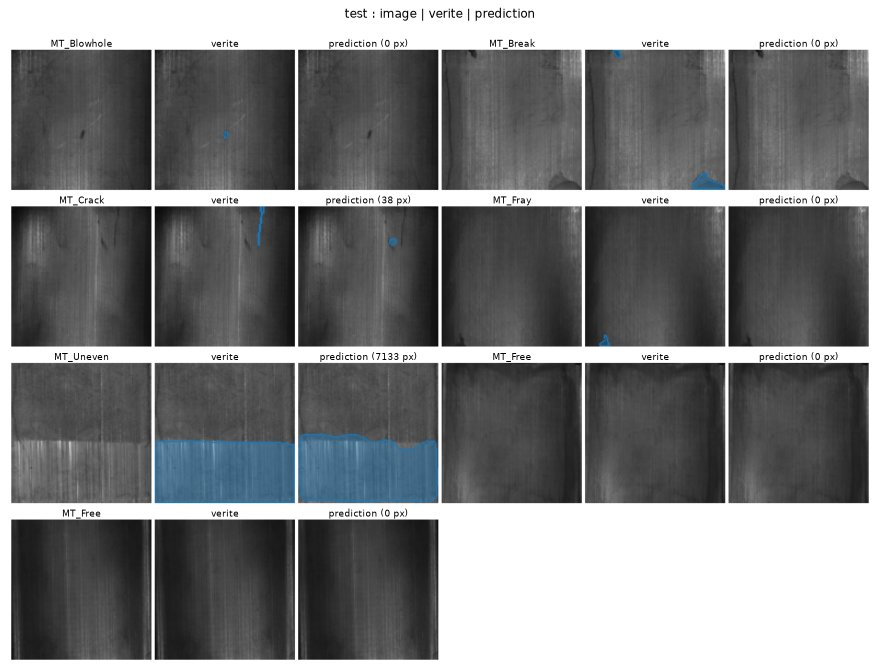

In [11]:
# une image par type de defaut + 2 images saines
shown = list(test_df[test_has_defect].groupby("label").head(1).index) + list(test_df[~test_has_defect].index[:2])
pred_test = predict_classes(test_probs, chosen_threshold).numpy()  # masques predits avec le seuil choisi
images = []  # images a afficher
titles = []  # titres correspondants
for i in shown:  # pour chaque image choisie
    gray = (x_test[i, 0].numpy() * 255).astype(np.uint8)  # image grise remise en 0-255 pour l'affichage
    # trois vues : l'image seule, avec la verite, avec la prediction
    images += [gray, viz.overlay_mask(gray, y_test[i].numpy()), viz.overlay_mask(gray, pred_test[i])]
    titles += [test_df.loc[i, "label"], "verite", f"prediction ({int(pred_test[i].sum())} px)"]  # classe, "verite", pixels predits
viz.grid(images, titles, ncols=6, size=1.8, suptitle="test : image | verite | prediction")  # 6 vignettes par ligne = 2 images x 3 vues

## Etape 12 - Sauvegarder et exporter : normalisation et softmax DANS le graphe

Le programme de production envoie une image grise dans [0, 1] (1 canal) et recoit une
probabilite par classe et par pixel. Verification sur un lot de 3 (export avec un lot de 2) ;
la carte du modele donne les reglages choisis sur la validation.

In [12]:
model = model.eval().cpu()  # mode evaluation et retour sur CPU pour l'export
onnx_path = OUT / "model.onnx"  # fichier ONNX : le modele dans un format lisible sans PyTorch (production)
with warnings.catch_warnings():  # dans ce bloc, les avertissements sont geres a part ...
    warnings.simplefilter("ignore")  # ... et masques (l'export en produit beaucoup)
    torch.onnx.export(  # fait passer un exemple dans le modele, enregistre les operations et les ecrit au format ONNX
        model,  # le modele a exporter (normalisation et softmax compris)
        (x_val[:2],),  # exemple d'entree : un lot de 2 images de validation
        str(onnx_path),  # chemin du fichier a ecrire
        input_names=["input"],  # nom de l'entree dans le graphe ONNX
        output_names=["probabilities"],  # nom de la sortie
        dynamic_axes={"input": {0: "batch"}, "probabilities": {0: "batch"}},  # la taille du lot (axe 0) reste libre
        opset_version=18,  # version du jeu d'operations ONNX
        dynamo=False,  # exporteur classique (par tracage), stable pour ce modele
    )
session = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])  # charge le fichier ONNX dans onnxruntime (CPU)
with torch.no_grad():  # sans gradient : simple prediction
    expected = model(x_val[:3]).numpy()  # reponse de PyTorch sur 3 images (lot de taille differente : teste l'axe libre)
got = session.run(None, {"input": x_val[:3].numpy()})[0]  # reponse d'onnxruntime sur les memes images
diff = float(np.abs(expected - got).max())  # plus grand ecart entre les deux reponses
assert diff <= 1e-4 + 1e-3 * float(np.abs(expected).max()), f"ecart ONNX / PyTorch {diff:.2e}"  # doivent concorder, sinon arret


def latency_ms(fn, runs: int = 20) -> float:  # temps moyen d'un appel de fn, en millisecondes
    for _ in range(2):  # 2 appels de chauffe non chronometres ...
        fn()  # ... (le premier appel est toujours plus lent : allocations, caches)
    start = time.perf_counter()  # chrono precis
    for _ in range(runs):  # `runs` appels chronometres
        fn()  # un appel du modele
    return round(1000 * (time.perf_counter() - start) / runs, 2)  # duree moyenne en ms, arrondie a 2 decimales


one = x_val[:1]  # une seule image (lot de 1) : la latence vue par la production
with torch.no_grad():  # sans gradient
    latency = {  # latence des deux moteurs
        "torch_cpu_ms": latency_ms(lambda: model(one)),  # PyTorch sur CPU (lambda : petite fonction sans nom)
        "onnxruntime_cpu_ms": latency_ms(lambda: session.run(None, {"input": one.numpy()})),  # onnxruntime sur CPU
    }
print(f"ONNX verifie : ecart max {diff:.1e} | {onnx_path.stat().st_size / 1e6:.1f} Mo | latence {latency}")  # ecart, taille, latences

card = {  # carte du modele : tout ce que la production doit savoir pour l'utiliser
    "task": "segmentation",  # type de tache
    "model_name": "unet_resnet18",  # nom du modele
    "created_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),  # date et heure de creation (UTC)
    # versions des bibliotheques utilisees
    "framework": {"torch": torch.__version__, "onnxruntime": ort.__version__, "segmentation_models_pytorch": smp.__version__},
    "input": {  # description de l'entree attendue
        "name": "input",  # nom de l'entree dans le graphe ONNX
        "layout": "NCHW",  # ordre des axes : lot, canaux, hauteur, largeur
        "height": IMAGE_SIZE,  # hauteur en pixels
        "width": IMAGE_SIZE,  # largeur en pixels
        "channels": in_channels,  # nombre de canaux
        "color": "GRAY" if in_channels == 1 else "RGB",  # gris ou couleur
        "dtype": "float32",  # nombres a virgule sur 32 bits
        "scale": "divide by 255 (8 bits) or 65535 (16 bits)",  # mise a l'echelle [0, 1] a faire avant l'envoi
        "mean": [],  # vide : la normalisation est deja dans le modele
        "std": [],  # vide aussi, meme raison
        "resize": "stretch",  # redimensionnement en etirant (proportions non conservees)
        "letterbox_pad_value": None,  # pas de letterbox (bandes ajoutees pour garder les proportions)
        "dynamic_batch": True,  # taille de lot libre
        "read_color": COLOR,  # mode de lecture de l'image
    },
    "preprocess": [{"name": "resize", "size": IMAGE_SIZE, "interpolation": "auto"}],  # pretraitement : resize, interpolation automatique
    "outputs": [  # description des sorties
        {  # une seule sortie
            "name": "probabilities",  # son nom
            "shape": ["batch", len(CLASS_NAMES), IMAGE_SIZE, IMAGE_SIZE],  # sa forme : lot, classes, hauteur, largeur
            "description": "probabilite de chaque classe par pixel (softmax)",  # ce qu'elle contient
        }
    ],
    "class_names": CLASS_NAMES,  # noms des classes, dans l'ordre des canaux de sortie
    "thresholds": {"defect_probability": chosen_threshold, "min_defect_area": float(chosen_area)},  # reglages choisis sur la validation
    "postprocess": {  # regles de decision a appliquer apres le modele
        # regle de classe d'un pixel
        "classes": "2 classes : pixel defaut si probabilities[1] > defect_probability ; sinon argmax sur les classes",
        "decision": "image signalee si le nombre de pixels de defaut >= min_defect_area",  # regle de decision par image
        "normalization": "incluse dans le modele (entree dans [0, 1])",  # rien a normaliser cote production
    },
    # metriques du test (reglages choisis), arrondies a 4 decimales
    "metrics": {k: round(chosen_report[k], 4) for k in ("miou", "miou_defects", "mdice_defects", "image_recall", "image_false_alarm_rate")},
    "latency_ms": latency,  # latences mesurees
    "files": {"onnx": "model.onnx"},  # fichier du modele, a cote de la carte
    "notes": f"U-Net ecrit dans le notebook 12 ; {best_epoch} epoques retenues ; ecart ONNX / PyTorch {diff:.1e}",  # note libre
}
(OUT / "model_card.json").write_text(json.dumps(card, indent=2), encoding="utf-8")  # ecrit la carte en JSON lisible
print("ecrit :", sorted(p.name for p in OUT.iterdir()))  # liste les fichiers du dossier de sortie

ONNX verifie : ecart max 1.2e-05 | 57.3 Mo | latence {'torch_cpu_ms': 24.08, 'onnxruntime_cpu_ms': 13.36}
ecrit : ['model.onnx', 'model_card.json', 'split.csv']


## Resultats

Reference : la recette `unet_resnet18_tile_cpu` (meme decoupage, 128 px, 15 epoques sur CPU)
donne IoU defauts 0,705, Dice 0,827, rappel image 0,61 et 1,6 % de fausses alarmes au seuil 0,5
et 10 pixels. Le mode QUICK n'entraine que 8 epoques : il montre la chaine et l'ordre de
grandeur, pas le meilleur modele.

In [13]:
results = pd.DataFrame(  # tableau de comparaison notebook / recette
    [  # deux lignes
        {  # ligne 1 : ce notebook
            "source": f"notebook 12 ({best_epoch} epoques, seuil {chosen_threshold}, surface {chosen_area})",  # description
            # ** recopie dans la ligne les 4 metriques principales du test, arrondies a 3 decimales
            **{k: round(chosen_report[k], 3) for k in ("miou_defects", "mdice_defects", "image_recall", "image_false_alarm_rate")},
            "entrainement_s": round(train_seconds),  # duree d'entrainement en secondes
            "ms_par_image": round(ms_per_image, 1),  # temps de prediction par image
        },
        {  # ligne 2 : la recette de reference
            "source": "recette unet_resnet18_tile_cpu (15 epoques, 0.5, 10 px)",  # description
            "miou_defects": 0.705,  # IoU des defauts obtenu par la recette
            "mdice_defects": 0.827,  # Dice des defauts
            "image_recall": 0.608,  # rappel image
            "image_false_alarm_rate": 0.016,  # taux de fausses alarmes
            "entrainement_s": 640,  # duree d'entrainement en secondes
            "ms_par_image": None,  # non mesure
        },
    ]
)
display(results)  # affiche le tableau

,source,miou_defects,mdice_defects,image_recall,image_false_alarm_rate,entrainement_s,ms_par_image
0,"notebook 12 (8 epoques, seuil 0.3, surface 40)",0.505,0.671,0.278,0.000,375,15.2
1,"recette unet_resnet18_tile_cpu (15 epoques, 0....",0.705,0.827,0.608,0.016,640,NaN


## Adapter a tes donnees

- Rangement image + masque de meme nom : changer `DATA_DIR`, `EXTENSIONS` et `COLOR`.
  Masques dans un autre dossier : adapter la ligne `mask = ...` de `image_mask_catalog`.
- Plusieurs classes de defaut : un masque dont la VALEUR est l'indice de classe (0 = fond),
  `CLASS_NAMES` complete, et `predict_classes` prend l'argmax (plus de seuil binaire).
- Pas de quasi-doublons possibles (une image par piece) : l'etape 2 trouve des groupes de
  taille 1 et le decoupage devient un decoupage stratifie classique. Des pieces connues
  (numero de bobine dans le nom) : remplir la colonne `group` avec ce numero.
- Defauts minuscules : `IMAGE_SIZE` plus grand ou des tuiles ; regler seuil et surface sur la
  validation (etape 11, "regler le seuil et la surface minimale").

## Passer en production

La meme experience en mode production (`recipes/segmentation/configs/unet_resnet18_tile_cpu.yaml`) :

```yaml
data: {root: data/raw/magnetic_tile, layout: image_mask, extensions: [".jpg"], color: gray,
       groups_csv: outputs/explore/magnetic_tile/groups.csv}
mask_mode: binary
split: {file: outputs/segmentation/tile_split.csv, strategy: grouped, val_fraction: 0.15, test_fraction: 0.2}
preprocess: [{name: resize, size: 128}]
augment: [{name: hflip}, {name: vflip}]
model: {architecture: unet, encoder: resnet18, encoder_weights: imagenet}
train: {epochs: 15, batch_size: 16, lr: 1.0e-3, encoder_lr_factor: 0.1, loss: dice_ce, patience: 4}
evaluation: {threshold: 0.5, min_defect_area: 10}
```

```
python recipes/explore/scripts/check_dataset.py --config recipes/explore/configs/magnetic_tile.yaml   # groups.csv
python recipes/segmentation/scripts/run.py --config recipes/segmentation/configs/unet_resnet18_tile_cpu.yaml
python -m vtb.serve --model outputs/notebooks/12_segmentation      # le modele du notebook, servi tel quel
```

Controle : le predicteur de production (numpy, OpenCV, onnxruntime, sans PyTorch) relit le
dossier exporte par ce notebook et doit compter les memes pixels de defaut ; groupes et
decoupage doivent etre ceux de la recette.

In [14]:
from vtb.serve.predictor import OnnxPredictor  # noqa: E402 - production seulement dans cette section (predicteur sans PyTorch)

predictor = OnnxPredictor(OUT)  # charge le modele ONNX et sa carte depuis le dossier exporte
picked = list(test_df[test_has_defect].index[:6]) + list(test_df[~test_has_defect].index[:2])  # 6 images a defaut + 2 saines
gaps = []  # ecarts de comptage de pixels entre production et notebook
for i in picked:  # pour chaque image choisie
    result = predictor(read_image(test_df.loc[i, "path"], predictor.color))  # prediction de production depuis l'image brute
    gaps.append(abs(result["defect_pixels"] - int(pred_test[i].sum())))  # ecart du nombre de pixels de defaut
print(f"predicteur de production : ecart max {max(gaps)} pixel(s) de defaut sur {len(picked)} images")  # plus grand ecart
assert max(gaps) <= 2, "le predicteur de production ne reproduit pas le notebook"  # tolere 2 pixels (petits ecarts d'arrondi)

for name, theirs_path, column in (  # pour chaque fichier de la recette a comparer :
    ("groupes", Path("outputs/explore/magnetic_tile/groups.csv"), "group"),  # les groupes de quasi-doublons
    ("decoupage", Path("outputs/segmentation/tile_split.csv"), "split"),  # le decoupage train / val / test
):
    if theirs_path.exists():  # si la recette a deja ete lancee
        theirs = pd.read_csv(theirs_path, keep_default_na=False).set_index("path")[column]  # sa colonne, indexee par chemin
        ours = split.set_index("path")[column]  # notre colonne, indexee par chemin
        # identique si chaque image a la meme valeur des deux cotes (reindex aligne les deux tableaux par chemin)
        print(f"{name} : identique a la production = {bool((theirs.reindex(ours.index) == ours).all())}")
    else:  # sinon (recette pas encore lancee)
        print(f"{name} : fichier de production absent ({theirs_path})")  # signale le fichier manquant

predicteur de production : ecart max 0 pixel(s) de defaut sur 8 images
groupes : identique a la production = True
decoupage : identique a la production = True


## Pour aller plus loin

- Autres architectures : `smp.UnetPlusPlus`, `smp.FPN`, `smp.DeepLabV3Plus` (meme encodeur,
  meme boucle) ; recette : `deeplabv3plus_resnet18_tile.yaml`, `unetplusplus_resnet34_tile.yaml`.
- Quel defaut ? Une classe par type (`unet_resnet18_tile_multiclass.yaml`) : 6 classes, argmax.
- Une forme par objet separe : segmentation d'instances YOLO11-seg (notebook 08).